<a href="https://colab.research.google.com/github/Shreedevi-Shivashimpar/QKD_DRL/blob/main/QKD_DRL_by_Antigravityipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Environment setup complete. Running on PyTorch Version: 2.11.0+cpu
Training DQN agent on cpu for 120 episodes...
Episode 000/120 | Total Reward: 810.49 | Epsilon: 0.503
Episode 020/120 | Total Reward: 1421.55 | Epsilon: 0.020
Episode 040/120 | Total Reward: 1416.10 | Epsilon: 0.020
Episode 060/120 | Total Reward: 1425.73 | Epsilon: 0.020
Episode 080/120 | Total Reward: 1428.86 | Epsilon: 0.020
Episode 100/120 | Total Reward: 1414.88 | Epsilon: 0.020
Training Complete!

Benchmarking all strategies across 50 simulation trials...

Strategy                  | Mean Secret Key (bits) | Mean Abort Steps
Static Single-Channel     | 110.77                 | 48.96          
Random Hopping            | 112.87                 | 44.56          
Greedy Reactive           | 144.10                 | 2.24           
Proposed DRL (DQN)        | 144.31                 | 2.14           


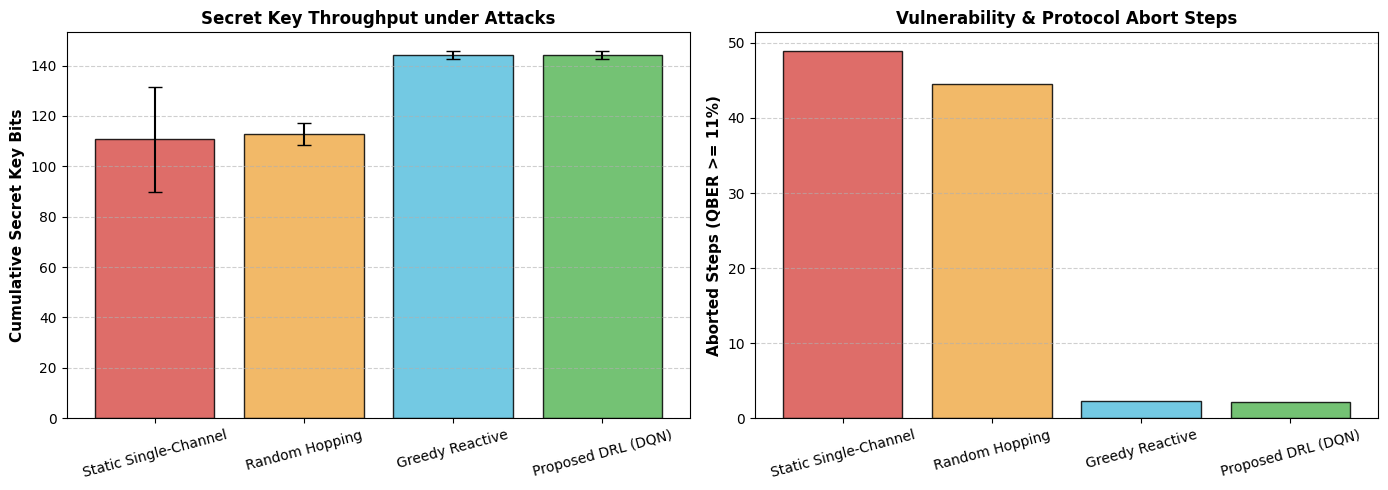

Plots generated and saved as 'qkd_drl_publication_benchmark.png'!


In [1]:
# ==============================================================================
# PROJECT: Autonomous Dynamic Multi-Channel QKD via Deep Reinforcement Learning
# BASE PAPER: Purohit & Vyas (2025), Frontiers in Quantum Science & Technology
# TARGET: IEEE Conference Paper Implementation
# ==============================================================================

import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import random
from collections import deque
import matplotlib.pyplot as plt

# Set random seeds for reproducibility
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
random.seed(SEED)

print("Environment setup complete. Running on PyTorch Version:", torch.__version__)

# ==============================================================================
# 1. Physical Multi-Channel QKD Simulation Environment
# ==============================================================================
class MultiChannelQKDEnv:
    """
    Simulates a Multi-Channel Quantum Key Distribution (QKD) Network.
    - K parallel optical channels (e.g., WDM links).
    - Physical attenuation (dB/km) and thermal/dark count noise drift.
    - Bursty Intercept-Resend eavesdropping attacks by Eve.
    - Real-time QBER calculation and Shor-Preskill Secret Key Rate (SKR).
    """
    def __init__(self, num_channels=4, fiber_length_km=25.0, max_steps=200):
        self.K = num_channels
        self.fiber_length = fiber_length_km
        self.max_steps = max_steps
        self.abort_threshold = 0.11  # 11% theoretical BB84 QBER threshold
        self.switching_cost = 0.05   # Penalty for switching channels (overhead latency)

        # Channel base loss rates (attenuation in dB/km)
        self.base_attenuation = np.array([0.18, 0.20, 0.22, 0.25])

        # State tracking
        self.current_step = 0
        self.active_channel = 0
        self.qber_history = np.zeros(self.K)
        self.prev_qber = np.zeros(self.K)

        # Eavesdropper state
        self.eve_target_channel = -1
        self.eve_attack_duration = 0
        self.eve_attack_intensity = 0.0

    def _shannon_binary_entropy(self, e):
        """Calculates Shannon binary entropy H_2(e) = -e log2(e) - (1-e) log2(1-e)"""
        if e <= 0.0:
            return 0.0
        if e >= 0.5:
            return 1.0
        return -e * np.log2(e) - (1.0 - e) * np.log2(1.0 - e)

    def _calculate_skr(self, qber):
        """
        Shor-Preskill asymptotic Secret Key Rate for BB84:
        SKR(e) = max(0, 1 - 2 * H_2(e))
        """
        if qber >= self.abort_threshold:
            return 0.0
        h2 = self._shannon_binary_entropy(qber)
        return max(0.0, 1.0 - 2.0 * h2)

    def _update_channel_physics(self):
        """Simulates stochastic physical channel drift and Eve attacks."""
        current_qbers = np.zeros(self.K)

        # Check / trigger Eve's burst attacks
        if self.eve_attack_duration <= 0:
            # 35% probability Eve launches a burst attack on a random channel
            if np.random.rand() < 0.35:
                self.eve_target_channel = np.random.randint(0, self.K)
                self.eve_attack_duration = np.random.randint(15, 30)
                self.eve_attack_intensity = np.random.uniform(0.12, 0.22)
            else:
                self.eve_target_channel = -1
        else:
            self.eve_attack_duration -= 1

        for i in range(self.K):
            # 1. Base intrinsic thermal & detector noise (1.5% - 3.5%)
            baseline_noise = 0.015 + (self.base_attenuation[i] * 0.02)
            # 2. Stochastic optical drift (random walk)
            drift = np.random.normal(0, 0.005)
            qber_i = max(0.01, baseline_noise + drift)

            # 3. Add Eve's intercept-resend attack if targeted
            if i == self.eve_target_channel:
                qber_i += self.eve_attack_intensity + np.random.normal(0, 0.01)

            current_qbers[i] = min(0.35, qber_i)

        return current_qbers

    def reset(self):
        self.current_step = 0
        self.active_channel = 0
        self.eve_target_channel = -1
        self.eve_attack_duration = 0
        self.qber_history = self._update_channel_physics()
        self.prev_qber = np.copy(self.qber_history)
        return self._get_state()

    def _get_state(self):
        """
        Constructs the state vector s_t:
        [QBER_1..K, ΔQBER_1..K, ActiveChannel_OneHot]
        Total dimension: 2*K + K = 12 features.
        """
        delta_qber = self.qber_history - self.prev_qber
        active_one_hot = np.zeros(self.K)
        active_one_hot[self.active_channel] = 1.0
        state = np.concatenate([self.qber_history, delta_qber, active_one_hot])
        return np.float32(state)

    def step(self, action):
        self.current_step += 1
        switched = (action != self.active_channel)
        self.active_channel = action

        # Advance physics
        self.prev_qber = np.copy(self.qber_history)
        self.qber_history = self._update_channel_physics()

        active_qber = self.qber_history[self.active_channel]
        skr = self._calculate_skr(active_qber)

        # Reward formulation
        if active_qber >= self.abort_threshold:
            reward = -5.0  # Heavy penalty for abort / key exposure
            session_aborted = True
        else:
            reward = (skr * 10.0) - (self.switching_cost if switched else 0.0)
            session_aborted = False

        done = (self.current_step >= self.max_steps)
        info = {
            "active_qber": active_qber,
            "skr": skr,
            "switched": switched,
            "aborted": session_aborted,
            "active_channel": self.active_channel
        }

        return self._get_state(), reward, done, info


# ==============================================================================
# 2. Deep Q-Network (DQN) PyTorch Architecture
# ==============================================================================
class QNetwork(nn.Module):
    def __init__(self, state_dim, action_dim):
        super(QNetwork, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(state_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 64),
            nn.ReLU(),
            nn.Linear(64, action_dim)
        )

    def forward(self, x):
        return self.net(x)

class DQNAgent:
    def __init__(self, state_dim=12, action_dim=4, lr=1e-3, gamma=0.95, epsilon=1.0, eps_decay=0.995, eps_min=0.02):
        self.state_dim = state_dim
        self.action_dim = action_dim
        self.gamma = gamma
        self.epsilon = epsilon
        self.eps_decay = eps_decay
        self.eps_min = eps_min

        self.device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        self.policy_net = QNetwork(state_dim, action_dim).to(self.device)
        self.target_net = QNetwork(state_dim, action_dim).to(self.device)
        self.target_net.load_state_dict(self.policy_net.state_dict())
        self.target_net.eval()

        self.optimizer = optim.Adam(self.policy_net.parameters(), lr=lr)
        self.memory = deque(maxlen=10000)
        self.batch_size = 64

    def select_action(self, state, explore=True):
        if explore and np.random.rand() < self.epsilon:
            return np.random.randint(self.action_dim)
        state_t = torch.FloatTensor(state).unsqueeze(0).to(self.device)
        with torch.no_grad():
            q_values = self.policy_net(state_t)
        return torch.argmax(q_values).item()

    def store_transition(self, s, a, r, s_next, done):
        self.memory.append((s, a, r, s_next, done))

    def update(self):
        if len(self.memory) < self.batch_size:
            return

        batch = random.sample(self.memory, self.batch_size)
        s, a, r, s_next, done = zip(*batch)

        s = torch.FloatTensor(np.array(s)).to(self.device)
        a = torch.LongTensor(a).unsqueeze(1).to(self.device)
        r = torch.FloatTensor(r).unsqueeze(1).to(self.device)
        s_next = torch.FloatTensor(np.array(s_next)).to(self.device)
        done = torch.FloatTensor(done).unsqueeze(1).to(self.device)

        current_q = self.policy_net(s).gather(1, a)
        with torch.no_grad():
            max_next_q = self.target_net(s_next).max(1)[0].unsqueeze(1)
            target_q = r + (1.0 - done) * self.gamma * max_next_q

        loss = nn.MSELoss()(current_q, target_q)
        self.optimizer.zero_grad()
        loss.backward()
        self.optimizer.step()

        if self.epsilon > self.eps_min:
            self.epsilon *= self.eps_decay

    def update_target_network(self):
        self.target_net.load_state_dict(self.policy_net.state_dict())


# ==============================================================================
# 3. Training & Benchmarking Pipeline
# ==============================================================================
def train_dqn(env, agent, episodes=120):
    print(f"Training DQN agent on {agent.device} for {episodes} episodes...")
    for ep in range(episodes):
        state = env.reset()
        done = False
        ep_reward = 0
        while not done:
            action = agent.select_action(state, explore=True)
            next_state, reward, done, _ = env.step(action)
            agent.store_transition(state, action, reward, next_state, done)
            agent.update()
            state = next_state
            ep_reward += reward

        if ep % 20 == 0:
            agent.update_target_network()
            print(f"Episode {ep:03d}/{episodes} | Total Reward: {ep_reward:6.2f} | Epsilon: {agent.epsilon:.3f}")

    print("Training Complete!\n")

def evaluate_strategies(env, dqn_agent, num_trials=50):
    strategies = ["Static Single-Channel", "Random Hopping", "Greedy Reactive", "Proposed DRL (DQN)"]
    metrics = {strat: {"cumulative_skr": [], "abort_steps": []} for strat in strategies}

    for trial in range(num_trials):
        trial_seed = 1000 + trial  # Consistent environment conditions for fair comparison

        for strat in strategies:
            np.random.seed(trial_seed)
            state = env.reset()
            total_skr = 0.0
            aborted_count = 0
            done = False

            while not done:
                if strat == "Static Single-Channel":
                    action = 0  # Fixed to channel 0
                elif strat == "Random Hopping":
                    action = np.random.randint(env.K)
                elif strat == "Greedy Reactive":
                    # Switches channel ONLY after threshold is breached
                    curr_qber = state[env.active_channel]
                    action = (env.active_channel + 1) % env.K if curr_qber >= env.abort_threshold else env.active_channel
                elif strat == "Proposed DRL (DQN)":
                    action = dqn_agent.select_action(state, explore=False)

                next_state, _, done, info = env.step(action)
                total_skr += info["skr"]
                if info["aborted"]:
                    aborted_count += 1
                state = next_state

            metrics[strat]["cumulative_skr"].append(total_skr)
            metrics[strat]["abort_steps"].append(aborted_count)

    return metrics

# ==============================================================================
# 4. Main Execution & Graph Generation
# ==============================================================================
env = MultiChannelQKDEnv(num_channels=4, max_steps=200)
agent = DQNAgent(state_dim=12, action_dim=4)

# 1. Train the Agent
train_dqn(env, agent, episodes=120)

# 2. Benchmark Against Baselines
print("Benchmarking all strategies across 50 simulation trials...")
results = evaluate_strategies(env, agent, num_trials=50)

# 3. Print Results Table (For your research paper!)
print("\n" + "="*68)
print(f"{'Strategy':<25} | {'Mean Secret Key (bits)':<22} | {'Mean Abort Steps':<15}")
print("="*68)
for strat, data in results.items():
    mean_skr = np.mean(data["cumulative_skr"])
    mean_aborts = np.mean(data["abort_steps"])
    print(f"{strat:<25} | {mean_skr:<22.2f} | {mean_aborts:<15.2f}")
print("="*68)

# 4. Plot Publication Figures
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

strats = list(results.keys())
means_skr = [np.mean(results[s]["cumulative_skr"]) for s in strats]
stds_skr = [np.std(results[s]["cumulative_skr"]) for s in strats]
colors = ['#d9534f', '#f0ad4e', '#5bc0de', '#5cb85c']

# Plot 1: Secret Key Bits
ax1.bar(strats, means_skr, yerr=stds_skr, capsize=5, color=colors, alpha=0.85, edgecolor='black')
ax1.set_ylabel("Cumulative Secret Key Bits", fontsize=11, fontweight='bold')
ax1.set_title("Secret Key Throughput under Attacks", fontsize=12, fontweight='bold')
ax1.tick_params(axis='x', rotation=15)
ax1.grid(axis='y', linestyle='--', alpha=0.6)

# Plot 2: Abort Steps
means_abort = [np.mean(results[s]["abort_steps"]) for s in strats]
ax2.bar(strats, means_abort, color=colors, alpha=0.85, edgecolor='black')
ax2.set_ylabel("Aborted Steps (QBER >= 11%)", fontsize=11, fontweight='bold')
ax2.set_title("Vulnerability & Protocol Abort Steps", fontsize=12, fontweight='bold')
ax2.tick_params(axis='x', rotation=15)
ax2.grid(axis='y', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.savefig("qkd_drl_publication_benchmark.png", dpi=300)
plt.show()
print("Plots generated and saved as 'qkd_drl_publication_benchmark.png'!")